# Fleet Force | Modelo analítico de eficiência e custos

### Diagnóstico de consumo, benchmarking e oportunidades de gestão de frotas

O Fleet Force transforma registros operacionais em indicadores para apoiar decisões sobre custos de veículos. Este estudo demonstra três capacidades do produto:

| Funcionalidade | Resultado |
|---|---|
| **US01 · Consolidar custos** | Organizar despesas, distâncias e consumo informado por veículo |
| **US02 · Comparar desempenho** | Comparar veículos com pares de mesmo modelo e consultar uma referência pública complementar |
| **US03 · Priorizar oportunidades** | Identificar desvios estatísticos relevantes e simular seu impacto financeiro |

**Fluxo:** fontes públicas → preparação → indicadores → elegibilidade → comparação entre pares → referência externa → cenários → visualizações.

**Bases:** UFMG (dados operacionais de 2025), Inmetro/PBEV (tabela de 2026) e ANP (preços de Minas Gerais, 1º semestre de 2026).

A metodologia utiliza **regras estatísticas interpretáveis**, e não um modelo treinado de Machine Learning. Os alertas indicam casos para investigação, sem comprovar consumo indevido nem economia recuperável.

**Execução:** coloque os três arquivos de entrada na mesma pasta do notebook, configure `BASE_DIR` se necessário e execute as células em ordem.

## 1. Preparação do ambiente

Parâmetros de análise e regras de elegibilidade. Os limiares representam critérios exploratórios de triagem e priorização, não limites técnicos universais de fabricantes.

In [3]:
%pip install -q "pillow<13" pdfplumber matplotlib

In [4]:
from pathlib import Path
import re
import warnings
import unicodedata
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber
from IPython.display import display

pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

BASE_DIR = Path.cwd()  # No Colab, use Path('/content') ou a pasta do Google Drive.
OUTPUT_DIR = BASE_DIR / "fleet_analysis_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUTS = {
    "fleet": BASE_DIR / "despesa-veiculos-ufmg-2025.pdf",
    "pbev": BASE_DIR / "Tabela PBEV 2026_25_AGO.pdf",
    "anp": BASE_DIR / "Preços semestrais - AUTOMOTIVOS_2026.01.csv",
}

MIN_DISTANCE_KM = 500
MIN_OTHER_PEERS = 3
PEER_MODERATE_OVERUSE = 0.10
PEER_HIGH_OVERUSE = 0.25
MIN_PRIORITY_EXCESS_LITERS = 25.0  # Volume mínimo para priorização descritiva.
PBEV_TOLERANCE = 0.20  # Diferença de consumo em litros por km.
PBEV_HEADER_DECLARED_MODELS = 976
ANP_STATE = "MG"
ANP_PERIOD_START = "2026-01-01"
ANP_PERIOD_END = "2026-06-30"

# Faixas de triagem operacional por categoria; não substituem especificações de cada veículo.
KMPL_SCREENING_BOUNDS = {
    "automovel": (1.0, 24.0),
    "picape": (1.0, 20.0),
    "van": (1.0, 20.0),
    "caminhao": (0.7, 15.0),
    "onibus": (0.7, 12.0),
    "outros": (0.5, 30.0),
    "desconhecido": (0.5, 30.0),
}

# Identificações amplas não definem um grupo homogêneo de comparação.
GENERIC_EXACT_MODEL_LABELS = {
    "CAMINHAO", "ONIBUS", "VAN", "MICRO ONIBUS", "M POLO",
    "MARCOPOLO", "COMIL", "RODOVIARIO", "ATHENAS", "ALLEGRO",
    "REBOQUE", "TANQUE", "CAVALO MEC", "BASCULANTE", "TRUCK",
}
GENERIC_MODEL_TOKENS = {"MARCOPOLO", "COMIL", "RODOVIARIO", "ATHENAS", "ALLEGRO"}

# Registros idênticos de origem ambígua não participam de comparação até validação documental.
DUPLICATE_REVIEW_MODE = "exclude_for_benchmark"

for label, path in INPUTS.items():
    if not path.is_file():
        raise FileNotFoundError(f"Arquivo '{label}' não encontrado: {path}")
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(chunk)
    print(f"{label.upper():>6}: {path.name} | {path.stat().st_size:,} bytes")
print("Diretório de exportação:", OUTPUT_DIR)

 FLEET: despesa-veiculos-ufmg-2025.pdf | 40,231 bytes
  PBEV: Tabela PBEV 2026_25_AGO.pdf | 3,387,564 bytes
   ANP: Preços semestrais - AUTOMOTIVOS_2026.01.csv | 71,694,743 bytes
Diretório de exportação: /content/fleet_analysis_outputs


## 2. Padronização e leitura das fontes

O relatório de frota e o catálogo de consumo são extraídos dos PDFs; a base de preços é lida em CSV. Identificadores, valores monetários, consumo e distâncias são normalizados antes dos cálculos.

In [5]:
def normalize_text(value) -> str:
    value = "" if pd.isna(value) else str(value)
    value = unicodedata.normalize("NFKD", value)
    value = "".join(c for c in value if not unicodedata.combining(c))
    value = value.upper().replace("&", " AND ")
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9]+", " ", value)).strip()


def parse_us_number(value) -> float:
    """Relatório UFMG: números como 3,650.38."""
    s = "" if value is None else str(value).strip()
    try:
        return float(s.replace(",", "")) if s else np.nan
    except ValueError:
        return np.nan


def parse_br_number(value) -> float:
    """PBEV: números como 14,5 ou células vazias."""
    s = "" if value is None else str(value).strip()
    if normalize_text(s) in {"", "ND", "NA", "N A", "N D"} or s in {"-", "\\"}:
        return np.nan
    try:
        return float(s.replace(".", "").replace(",", "."))
    except ValueError:
        return np.nan


def column_index(x, bounds):
    for i, (left, right) in enumerate(zip(bounds[:-1], bounds[1:])):
        if left <= x < right:
            return i
    return None


def show_table(df: pd.DataFrame, n=15):
    display(df.head(n).copy().round(3))


FLEET_BOUNDS = [35, 90, 180, 210, 260, 310, 360, 410, 455, 495, 545, 605, 655, 725, 780]
FLEET_COLUMNS = [
    "fleet_id", "model", "os_count", "labor_internal", "labor_external",
    "parts", "tires", "fuel_expense", "lubricant", "wash", "km",
    "kmpl_reported", "total_expense", "cost_per_km"
]

PBEV_BOUNDS = [
    175, 204, 233, 263, 296, 312, 329, 343, 356, 370, 388, 402,
    414, 426, 436, 443, 453, 463, 471, 481, 492, 505, 516, 526,
    540, 551, 563, 574, 585, 602, 619, 638, 658, 675
]
PBEV_COLUMNS = [
    "category", "brand", "model", "version", "motor", "propulsion",
    "transmission", "air_cond", "steering", "fuel_code",
    "nmog_nox", "co", "nox", "emissions_class",
    "co2_ethanol_fossil", "co2_gas_total", "co2_gas_fossil", "co2_vehp_fossil",
    "ethanol_city", "ethanol_highway", "ethanol_combined",
    "gas_city", "gas_highway", "gas_combined",
    "electric_city_gas", "electric_highway_gas",
    "electric_city_ethanol", "electric_highway_ethanol",
    "energy_mj_km", "electric_range_km", "pbe_category", "pbe_overall", "conpet"
]

### 2.1. Dados operacionais da frota

Cada registro conserva sua posição no documento original para garantir rastreabilidade. Registros integralmente idênticos são consolidados para os cálculos, enquanto as ocorrências originais permanecem disponíveis para conferência. Veículos cuja identidade dos lançamentos exige confirmação não entram nas comparações de eficiência.

In [6]:
def parse_fleet_pdf(path: Path) -> pd.DataFrame:
    rows = []
    with pdfplumber.open(path) as pdf:
        for page_num, page in enumerate(pdf.pages, start=1):
            words = page.extract_words(x_tolerance=1, y_tolerance=1.2, keep_blank_chars=False)
            anchors = sorted({
                round(w["top"], 2) for w in words
                if 40 <= w["x0"] < 90 and re.fullmatch(r"[A-Z0-9]{7}", w["text"])
            })
            for y in anchors:
                line = [w for w in words if abs(w["top"] - y) <= 0.8 and 35 <= w["x0"] < 780]
                buckets = [[] for _ in FLEET_COLUMNS]
                for w in line:
                    idx = column_index((w["x0"] + w["x1"]) / 2, FLEET_BOUNDS)
                    if idx is not None:
                        buckets[idx].append(w)
                values = [" ".join(w["text"] for w in sorted(b, key=lambda item: item["x0"])).strip()
                          for b in buckets]
                if re.fullmatch(r"[A-Z0-9]{7}", values[0]):
                    rec = dict(zip(FLEET_COLUMNS, values))
                    rec["source_page"] = page_num
                    rec["source_y"] = y
                    rows.append(rec)
    if not rows:
        raise ValueError("Nenhuma linha da frota extraída. Confira o layout do PDF.")
    df = pd.DataFrame(rows)
    for c in FLEET_COLUMNS:
        if c not in ("fleet_id", "model"):
            df[c] = df[c].map(parse_us_number)
    df["model_norm"] = df["model"].map(normalize_text)
    df.insert(0, "source_row_id", np.arange(1, len(df) + 1, dtype=int))
    return df


fleet_raw = parse_fleet_pdf(INPUTS["fleet"])
fleet_raw.to_csv(OUTPUT_DIR / "ufmg_linhas_originais.csv", index=False)

is_exact_duplicate = fleet_raw.duplicated(subset=FLEET_COLUMNS, keep=False)
duplicate_candidates = fleet_raw.loc[is_exact_duplicate].copy()
duplicate_candidates["audit_status"] = "pending_source_confirmation"
duplicate_candidates["source_context"] = "identical_rows_pending_origin_validation"
duplicate_candidates["duplicate_key"] = duplicate_candidates[FLEET_COLUMNS].astype(str).agg("|".join, axis=1).map(lambda v: hashlib.sha256(v.encode()).hexdigest()[:16])
duplicate_candidates["method"] = "single_occurrence_for_reporting"
duplicate_candidates.to_csv(OUTPUT_DIR / "ufmg_duplicatas_para_auditoria.csv", index=False)

fleet_rows = fleet_raw.drop_duplicates(subset=FLEET_COLUMNS, keep="first").copy()
fleet_rows["source_row_count"] = 1
fleet_rows["data_origin"] = "UFMG_PDF_2025"
fleet_rows["deduplication_decision"] = "identical_rows_collapsed"
fleet_rows["provisional_duplicate_vehicle"] = fleet_rows["fleet_id"].isin(
    duplicate_candidates["fleet_id"]
)

print(f"Registros extraídos: {len(fleet_raw):,}")
print(f"Veículos identificados: {fleet_raw['fleet_id'].nunique():,}")
print(f"Registros elegíveis à consolidação: {len(fleet_rows):,}")

Registros extraídos: 232
Veículos identificados: 217
Registros elegíveis à consolidação: 231


## 3. Indicadores operacionais por veículo

A quilometragem e o consumo em km/L são informados pela UFMG. O volume em litros é **estimado** a partir desses dois campos:

\[
L_{estimado}=\frac{\text{distância percorrida (km)}}{\text{eficiência informada (km/L)}}
\]

A consolidação também calcula despesas por quilômetro e a parcela da distância que possui dados suficientes para estimar litros.

In [7]:
def aggregate_fleet_rows(rows: pd.DataFrame) -> pd.DataFrame:
    clean = rows.copy()
    can_estimate = (
        clean["km"].gt(0)
        & clean["kmpl_reported"].gt(0)
        & np.isfinite(clean["kmpl_reported"])
    )
    clean["liters_est"] = np.where(
        can_estimate,
        clean["km"] / clean["kmpl_reported"],
        np.nan,
    )
    clean["km_covered"] = clean["km"].where(can_estimate, 0.0)
    clean["km_uncovered"] = clean["km"].where(~can_estimate & clean["km"].gt(0), 0.0)
    clean["liters_est"] = clean["liters_est"].replace([np.inf, -np.inf], np.nan)

    money = ["labor_internal", "labor_external", "parts", "tires", "fuel_expense",
             "lubricant", "wash", "total_expense"]
    agg = {c: "sum" for c in money}
    agg.update({
        "os_count": "sum", "km": "sum", "km_covered": "sum", "km_uncovered": "sum",
        "liters_est": lambda s: s.sum(min_count=1),
        "model": "first", "source_row_id": "count",
        "provisional_duplicate_vehicle": "max",
    })
    result = clean.groupby("fleet_id", as_index=False).agg(agg)
    result = result.rename(columns={"source_row_id": "row_count"})
    result["kmpl"] = result["km_covered"] / result["liters_est"].replace(0, np.nan)
    result["kmpl"] = result["kmpl"].replace([np.inf, -np.inf], np.nan)
    result["kmpl_coverage_pct"] = np.where(
        result["km"] > 0, result["km_covered"] / result["km"] * 100, np.nan
    )
    result["cost_per_km"] = result["total_expense"] / result["km"].replace(0, np.nan)
    result["fuel_cost_per_km_historical"] = result["fuel_expense"] / result["km"].replace(0, np.nan)
    result["model_norm"] = result["model"].map(normalize_text)
    result["liters_source"] = "estimated_from_distance_and_reported_kmpl"
    return result


fleet = aggregate_fleet_rows(fleet_rows)
print(f"Frota consolidada: {fleet['fleet_id'].nunique():,} veículos")
show_table(fleet[["fleet_id", "model", "km", "liters_est", "kmpl", "fuel_expense", "total_expense", "fuel_cost_per_km_historical"]], 12)

Frota consolidada: 217 veículos


,fleet_id,model,km,liters_est,kmpl,fuel_expense,total_expense,fuel_cost_per_km_historical
0,EXY2I64,MASTER,"4,431.00",505.25,8.77,"3,650.38","4,169.33",0.82
1,GMF1396,CAMINHAO,698.00,352.52,1.98,"2,785.84","22,007.24",3.99
2,GMF1756,VAN SPRINTER,"1,165.00",206.56,5.64,"1,312.78","1,312.78",1.13
3,GMF2414,CAMINHAO,"2,807.00","1,155.14",2.43,"7,789.40","8,715.26",2.77
4,GMF2794,CAMINHAO 608,"4,235.00",534.05,7.93,"3,464.63","3,464.63",0.82
5,GMF3118,M. POLO,"6,475.00","1,956.19",3.31,"14,957.67","15,157.77",2.31
6,GMF3242,PICK-UP,"1,022.00",119.95,8.52,769.50,"1,358.14",0.75
7,GMF3245,PICK-UP S10 2.2,0.00,NaN,NaN,"4,096.46","4,553.54",NaN
8,GMF3253,VAN SPRINTER,"3,134.00",401.80,7.80,"3,071.52","8,735.92",0.98
9,GMF3254,PICK-UP S10 2.2,"2,069.00",397.88,5.20,"2,666.35","4,152.81",1.29


## 4. Elegibilidade e qualidade dos indicadores

A triagem considera distância mínima, cobertura do consumo, plausibilidade por categoria operacional e consistência dos registros. Um veículo que exige revisão permanece no conjunto de dados, mas não influencia a referência dos demais.

In [8]:
def operational_category(model_norm: str) -> str:
    s = normalize_text(model_norm)
    tokens = set(s.split())
    if any(t in tokens for t in ["CAMINHAO", "TRUCK", "BASCULANTE", "CAVALO", "CARRETA"]):
        return "caminhao"
    if any(t in tokens for t in ["ONIBUS", "MICRO", "MARCOPOLO", "COMIL", "RODOVIARIO", "ATHENAS", "ALLEGRO"]):
        return "onibus"
    if any(t in tokens for t in ["PICK", "PIC", "S10", "AMAROK", "L200", "FRONTIER", "RANGER", "HILUX", "SAVEIRO", "STRADA"]):
        return "picape"
    if any(t in tokens for t in ["VAN", "SPRINTER", "DUCATO", "TRANSIT", "JUMPER", "MASTER"]):
        return "van"
    if any(t in tokens for t in ["REBOQUE", "TANQUE"]):
        return "outros"
    if s:
        return "automovel"
    return "desconhecido"


def quality_reasons(row):
    reasons = []
    if pd.isna(row["km"]) or row["km"] <= 0:
        reasons.append("missing_or_zero_distance")
    elif row["km"] < MIN_DISTANCE_KM:
        reasons.append("insufficient_distance")
    if pd.notna(row["km_uncovered"]) and row["km_uncovered"] > 0:
        reasons.append("incomplete_kmpl_coverage")
    if pd.isna(row["kmpl"]) or not np.isfinite(row["kmpl"]):
        reasons.append("kmpl_unavailable")
    else:
        lower, upper = KMPL_SCREENING_BOUNDS[row["vehicle_category"]]
        if row["kmpl"] < lower:
            reasons.append("kmpl_below_category_screening")
        if row["kmpl"] > upper:
            reasons.append("kmpl_above_category_screening")
    if row["provisional_duplicate_vehicle"]:
        reasons.append("duplicate_under_review")
    return reasons


fleet["vehicle_category"] = fleet["model_norm"].map(operational_category)
fleet["quality_reasons_list"] = fleet.apply(quality_reasons, axis=1)
fleet["quality_reason"] = fleet["quality_reasons_list"].map(lambda a: ";".join(a))
fleet["requires_review"] = fleet["quality_reasons_list"].map(lambda a: len(a) > 0)
fleet["valid_efficiency"] = ~fleet["requires_review"]
fleet["quality_status"] = np.where(fleet["valid_efficiency"], "eligible", "review_required")

quality_issues = fleet.loc[fleet["requires_review"],
    ["fleet_id", "model", "vehicle_category", "km", "kmpl", "km_uncovered", "quality_reason"]
].sort_values("fleet_id")

quality_by_category = (
    fleet.groupby("vehicle_category", as_index=False)
    .agg(vehicles=("fleet_id", "count"), eligible=("valid_efficiency", "sum"))
)
quality_by_category["eligibility_pct"] = (100 * quality_by_category["eligible"] / quality_by_category["vehicles"]).round(1)
print(f"Veículos elegíveis: {int(fleet['valid_efficiency'].sum())} / {len(fleet)}")
display(quality_by_category)

Veículos elegíveis: 199 / 217


,vehicle_category,vehicles,eligible,eligibility_pct
0,automovel,128,119,93.00
1,caminhao,14,13,92.90
2,onibus,22,20,90.90
3,outros,2,0,0.00
4,picape,36,32,88.90
5,van,15,15,100.00


## 5. Benchmark interno: comparação com veículos equivalentes

O desempenho de cada veículo é comparado à **mediana do consumo (km/L) dos demais veículos com a mesma identificação de modelo**, exigindo pelo menos três outros integrantes elegíveis. O próprio veículo não entra no cálculo da sua referência.

O método preserva os grupos com identificação genérica como **comparações exploratórias de baixa confiança**. Para os demais, o resultado tem confiança moderada, porque ano, motorização, combustível e condições de uso não estão completamente disponíveis nesta base.

**Indicadores:**

- Excesso relativo estimado: `mediana dos pares / km/L do veículo − 1`.
- Litros excedentes estimados: `km / km/L do veículo − km / mediana dos pares`.
- Prioridade: confiança moderada, diferença relativa de pelo menos 10% e volume estimado de pelo menos 25 L.

In [9]:
def is_generic_model(model_norm: str) -> bool:
    value = normalize_text(model_norm)
    tokens = set(value.split())
    return value in GENERIC_EXACT_MODEL_LABELS or bool(tokens & GENERIC_MODEL_TOKENS)


def peer_results(frame: pd.DataFrame) -> pd.DataFrame:
    valid = frame.loc[frame["valid_efficiency"]].copy()
    groups = {
        label: part.set_index("fleet_id")["kmpl"]
        for label, part in valid.groupby("model_norm", sort=False)
    }
    records = []
    for row in frame.itertuples(index=False):
        group = groups.get(row.model_norm, pd.Series(dtype=float))
        others = group.drop(index=row.fleet_id, errors="ignore") if row.valid_efficiency else pd.Series(dtype=float)
        n = len(others)
        can_compare = bool(row.valid_efficiency and n >= MIN_OTHER_PEERS)
        median = float(others.median()) if can_compare else np.nan
        ratio = row.kmpl / median if can_compare and median > 0 else np.nan
        overuse_pct = median / row.kmpl - 1 if can_compare and row.kmpl > 0 else np.nan
        excess_liters = (row.km_covered / row.kmpl - row.km_covered / median) if can_compare and median > 0 else np.nan
        generic = is_generic_model(row.model_norm)
        if not row.valid_efficiency:
            confidence, status = "insufficient", "review_data_quality"
        elif not can_compare:
            confidence, status = "insufficient", "insufficient_other_peers"
        elif generic:
            confidence, status = "low", "inconclusive_generic_model"
        elif overuse_pct >= PEER_HIGH_OVERUSE:
            confidence, status = "moderate", "high_relative_consumption_indication"
        elif overuse_pct >= PEER_MODERATE_OVERUSE:
            confidence, status = "moderate", "moderate_relative_consumption_indication"
        elif overuse_pct > 0:
            confidence, status = "moderate", "slightly_below_peers"
        else:
            confidence, status = "moderate", "at_or_above_peers"
        records.append({
            "fleet_id": row.fleet_id,
            "other_peer_count": n,
            "peer_median_kmpl": median,
            "peer_efficiency_ratio": ratio,
            "peer_overuse_pct": overuse_pct,
            "excess_liters_vs_peer_est": excess_liters,
            "peer_confidence": confidence,
            "peer_status": status,
            "model_identification_required": generic,
            "peer_reference_method": "same_normalized_model_leave_one_out",
        })
    return pd.DataFrame(records)

fleet = fleet.merge(peer_results(fleet), on="fleet_id", how="left", validate="one_to_one")
fleet["peer_positive_liters_est"] = (
    fleet["excess_liters_vs_peer_est"].clip(lower=0)
    .where(fleet["peer_confidence"].eq("moderate"))
)
fleet["priority_alert"] = (
    fleet["peer_confidence"].eq("moderate")
    & fleet["peer_overuse_pct"].ge(PEER_MODERATE_OVERUSE)
    & fleet["peer_positive_liters_est"].ge(MIN_PRIORITY_EXCESS_LITERS)
)
fleet["actionable_excess_liters_est"] = fleet["peer_positive_liters_est"].where(fleet["priority_alert"])
fleet["exploratory_excess_liters_est"] = (
    fleet["excess_liters_vs_peer_est"].clip(lower=0)
    .where(fleet["peer_confidence"].eq("low"))
)
fleet["peer_efficiency_percentile"] = (
    fleet["peer_efficiency_ratio"].where(fleet["peer_confidence"].eq("moderate"))
    .rank(pct=True) * 100
)
comparison_coverage = (
    fleet.groupby("peer_confidence", as_index=False)
    .agg(vehicles=("fleet_id", "count"), priority_cases=("priority_alert", "sum"))
)
print(f"Comparações internas com confiança moderada: {fleet['peer_confidence'].eq('moderate').sum()}")
print(f"Casos prioritários: {fleet['priority_alert'].sum()}")
display(comparison_coverage)

Comparações internas com confiança moderada: 97
Casos prioritários: 26


,peer_confidence,vehicles,priority_cases
0,insufficient,106,0
1,low,14,0
2,moderate,97,26


### 5.1. Distribuição dos grupos de comparação

As comparações de confiança moderada orientam o ranking de investigação. Os grupos de baixa confiança permanecem acessíveis para consulta, sem serem confundidos com alertas prioritários.

In [10]:
model_groups = (
    fleet.groupby(["model_norm", "peer_confidence"], as_index=False)
    .agg(vehicles=("fleet_id", "count"), eligible=("valid_efficiency", "sum"))
    .sort_values(["vehicles", "model_norm"], ascending=[False, True])
)
show_table(model_groups, 20)

,model_norm,peer_confidence,vehicles,eligible
25,KOMBI,moderate,27,27
64,SPACEFOX,moderate,16,16
1,AMAROK CD,moderate,11,11
71,UNO MILLE FIRE,moderate,9,9
4,CAMINHAO,low,8,8
18,FIESTA 1 6,moderate,8,8
32,MARCOPOLO,low,6,6
70,UNO MILLE,moderate,6,6
76,VAN SPRINTER,moderate,6,6
44,PALIO ELX FLEX,moderate,5,5


## 6. Benchmark externo: Inmetro / PBEV

O PBEV fornece uma segunda perspectiva para veículos leves. A extração registra a cobertura dos dados de origem e as associações são tratadas como **exploratórias**, já que a frota de 2025 pode incluir veículos de versões e anos diferentes daqueles presentes no catálogo de 2026.

In [11]:
PROPULSION_LABELS = {
    "COMBUSTAO": "Combustão", "ELETRICO": "Elétrico", "HIBRIDO": "Híbrido",
    "PLUG IN": "Plug-in", "PLUG IN HIBRIDO": "Plug-in",
}

def close_groups(values, tolerance=0.85):
    groups = []
    for v in sorted(float(y) for y in values):
        if not groups or v - groups[-1][-1] > tolerance:
            groups.append([v])
        else:
            groups[-1].append(v)
    return [float(np.median(v)) for v in groups]


def parse_pbev_pdf(path: Path):
    extracted, rejected, page_counts = [], [], []
    with pdfplumber.open(path) as pdf:
        for page_num, page in enumerate(pdf.pages, start=1):
            words = page.extract_words(x_tolerance=0.3, y_tolerance=0.3, keep_blank_chars=False)
            brand_y = [w["top"] for w in words if 204 <= w["x0"] < 233]
            model_y = [w["top"] for w in words if 233 <= w["x0"] < 263 and w["text"].strip()]
            propulsion_y = [
                w["top"] for w in words
                if 290 <= w["x0"] < 336 and normalize_text(w["text"]) in
                {"COMBUSTAO", "ELETRICO", "HIBRIDO", "PLUG", "IN", "HIBRIDO"}
            ]
            anchors = close_groups(brand_y + model_y + propulsion_y)
            accepted_page, rejected_page = 0, 0
            seen_y = []
            for y in anchors:
                candidates = []
                for tolerance in (0.65, 0.9, 1.2):
                    line = [w for w in words if abs(w["top"] - y) <= tolerance and 175 <= w["x0"] < 675]
                    buckets = [[] for _ in PBEV_COLUMNS]
                    for w in line:
                        idx = column_index((w["x0"] + w["x1"]) / 2, PBEV_BOUNDS)
                        if idx is not None:
                            buckets[idx].append(w)
                    values = [" ".join(w["text"] for w in sorted(b, key=lambda item: item["x0"])).strip() for b in buckets]
                    brand, model, prop = values[1], values[2], normalize_text(values[5])
                    valid = bool(
                        prop in PROPULSION_LABELS and
                        normalize_text(brand) not in {"", "MARCA"} and
                        normalize_text(model) not in {"", "MODELO"}
                    )
                    # Preferir a leitura mais concentrada em colunas identificáveis.
                    score = (4 if valid else 0) + int(bool(brand)) + int(bool(model)) + int(bool(prop))
                    candidates.append((score, -tolerance, valid, values, line, tolerance))
                _, _, valid, values, line, tolerance = max(candidates, key=lambda c: (c[0], c[1]))
                # Múltiplos anchors podem mapear a mesma linha; preservar só uma ocorrência próxima.
                if valid and any(abs(y - other_y) <= 1.5 for other_y in seen_y):
                    continue
                if valid:
                    seen_y.append(y)
                    values[5] = PROPULSION_LABELS[normalize_text(values[5])]
                    rec = dict(zip(PBEV_COLUMNS, values))
                    rec.update({"source_page": page_num, "source_y": round(y, 2),
                                "extraction_tolerance": tolerance})
                    extracted.append(rec)
                    accepted_page += 1
                else:
                    rejected.append({
                        "source_page": page_num, "source_y": round(y, 2),
                        "brand_raw": values[1], "model_raw": values[2],
                        "propulsion_raw": values[5],
                        "candidate_text": " ".join(w["text"] for w in sorted(line, key=lambda z: z["x0"]))[:500],
                        "reason": "non_data_or_unrecognized_row",
                    })
                    rejected_page += 1
            page_counts.append({"source_page": page_num, "accepted": accepted_page,
                                "rejected_candidates": rejected_page})
    if not extracted:
        raise ValueError('Nenhuma linha válida recuperada no PBEV. Verifique layout, PDF e parâmetros.')
    df = pd.DataFrame(extracted)
    for c in ['ethanol_city', 'ethanol_highway', 'ethanol_combined',
              'gas_city', 'gas_highway', 'gas_combined', 'energy_mj_km', 'electric_range_km']:
        df[c] = df[c].map(parse_br_number)
    df['model_norm'] = df['model'].map(normalize_text)
    df['brand_norm'] = df['brand'].map(normalize_text)
    reject_df = pd.DataFrame(rejected, columns=[
        'source_page','source_y','brand_raw','model_raw','propulsion_raw','candidate_text','reason'
    ])
    return df, reject_df, pd.DataFrame(page_counts)

pbev, pbev_rejected, pbev_pages = parse_pbev_pdf(INPUTS['pbev'])
pbev_reconciled = len(pbev) == PBEV_HEADER_DECLARED_MODELS
pbev_extraction_gap = PBEV_HEADER_DECLARED_MODELS - len(pbev)
pbev_audit_status = 'count_reconciled_pending_semantic_review' if pbev_reconciled else 'extraction_not_reconciled'
pbev.to_csv(OUTPUT_DIR / 'pbev_extracted_rows.csv', index=False, encoding='utf-8-sig')
pbev_rejected.to_csv(OUTPUT_DIR / 'pbev_rejected_candidates.csv', index=False, encoding='utf-8-sig')
pbev_pages.to_csv(OUTPUT_DIR / 'pbev_extraction_by_page.csv', index=False, encoding='utf-8-sig')
pd.DataFrame([{
    'declared': PBEV_HEADER_DECLARED_MODELS, 'extracted': len(pbev),
    'gap': pbev_extraction_gap, 'status': pbev_audit_status,
    'candidates_rejected': len(pbev_rejected),
    'disclaimer': 'Count equality does not establish record-by-record correctness.'
}]).to_csv(OUTPUT_DIR / 'pbev_reconciliation.csv', index=False, encoding='utf-8-sig')
print(f"Versões no catálogo: {len(pbev):,}")
print(f"Cobertura da extração: {len(pbev) / PBEV_HEADER_DECLARED_MODELS:.1%}")
print(f"Registros candidatos não incorporados: {len(pbev_rejected):,}")
display(pbev['propulsion'].value_counts().rename('versões').to_frame())
if not pbev_reconciled:
    warnings.warn("Cobertura incompleta do catálogo. O uso é exploratório; consulte a planilha de reconciliação.")

Versões no catálogo: 968
Cobertura da extração: 99.2%
Registros candidatos não incorporados: 37


,versões
propulsion,
Combustão,556
Elétrico,186
Híbrido,114
Plug-in,112


/tmp/ipykernel_1545/4117194261.py:104: UserWarning: Cobertura incompleta do catálogo. O uso é exploratório; consulte a planilha de reconciliação.
  warnings.warn("Cobertura incompleta do catálogo. O uso é exploratório; consulte a planilha de reconciliação.")


### 6.1. Associação de modelos e referência de consumo

A associação utiliza nomes normalizados e correspondências por palavras completas, excluindo categorias pesadas e identificações genéricas. A referência escolhida é o menor km/L disponível entre as variantes e combustíveis associados ao nome do modelo, para uma sinalização mais cautelosa. A correspondência textual não comprova equivalência de versão, ano ou combustível.

In [12]:
HEAVY_OR_GENERIC_TOKENS = {
    "CAMINHAO", "ONIBUS", "MICRO", "MARCOPOLO", "COMIL", "TANQUE",
    "CAVALO", "REBOQUE", "RODOVIARIO", "ATHENAS", "ALLEGRO"
}


def excluded_from_pbev(model_norm: str) -> bool:
    tokens = set(model_norm.split())
    return (model_norm in GENERIC_EXACT_MODEL_LABELS
            or is_generic_model(model_norm)
            or bool(tokens.intersection(HEAVY_OR_GENERIC_TOKENS)))


def pbev_benchmark_table(pbev_frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for r in pbev_frame.loc[pbev_frame["propulsion"].ne("Elétrico")].itertuples(index=False):
        for fuel_label, kmpl in [("ethanol", r.ethanol_combined), ("gasoline_or_diesel", r.gas_combined)]:
            if pd.notna(kmpl) and np.isfinite(kmpl) and kmpl > 0:
                rows.append({
                    "model_norm": r.model_norm,
                    "pbev_model": r.model,
                    "pbev_brands": r.brand,
                    "pbev_category": r.category,
                    "pbev_fuel_code": r.fuel_code,
                    "reference_fuel": fuel_label,
                    "reference_kmpl": kmpl,
                })
    if not rows:
        raise ValueError("Nenhuma referência km/L extraída do PBEV")
    long = pd.DataFrame(rows)
    compact = long.groupby("model_norm", as_index=False).agg(
        pbev_model=("pbev_model", "first"),
        pbev_brands=("pbev_brands", lambda s: ", ".join(sorted(set(s)))),
        pbev_categories=("pbev_category", lambda s: ", ".join(sorted(set(s)))),
        pbev_reference_count=("reference_kmpl", "size"),
        pbev_min_kmpl=("reference_kmpl", "min"),
        pbev_median_kmpl=("reference_kmpl", "median"),
        pbev_max_kmpl=("reference_kmpl", "max"),
    )
    return compact


def match_public_model(name: str, names: set[str]):
    if excluded_from_pbev(name):
        return None, "excluded_heavy_or_generic"
    if name in names:
        return name, "exact_name_only"
    # Uma correspondência precisa ocupar tokens completos; nomes ambíguos não são escolhidos.
    candidates = []
    padded = f" {name} "
    for c in names:
        if len(c) < 3:
            continue
        if f" {c} " in padded:
            candidates.append(c)
    if not candidates:
        return None, "no_match"
    max_len = max(len(c) for c in candidates)
    longest = sorted(c for c in candidates if len(c) == max_len)
    if len(longest) != 1:
        return None, "ambiguous_match"
    return longest[0], "contained_whole_tokens"


pbev_model_benchmark = pbev_benchmark_table(pbev)
model_names = set(pbev_model_benchmark["model_norm"])
matching = pd.DataFrame([
    {"model_norm": n, "pbev_model_norm": result[0], "pbev_match_method": result[1]}
    for n in fleet["model_norm"].unique()
    for result in [match_public_model(n, model_names)]
])
fleet = fleet.merge(matching, on="model_norm", how="left", validate="many_to_one")
public_reference = pbev_model_benchmark.rename(columns={"model_norm": "pbev_model_norm"})
fleet = fleet.merge(public_reference, on="pbev_model_norm", how="left", validate="many_to_one")
fleet["pbev_comparison_confidence"] = np.where(
    fleet["valid_efficiency"] & fleet["pbev_min_kmpl"].notna(),
    "exploratory_name_match", "unavailable"
)

print("Veículos associados ao catálogo:", int(fleet["pbev_model_norm"].notna().sum()))
print("Veículos elegíveis ao benchmark externo:", int(fleet["pbev_comparison_confidence"].eq("exploratory_name_match").sum()))
show_table(fleet.loc[fleet["pbev_comparison_confidence"].eq("exploratory_name_match"),
    ["fleet_id", "model", "pbev_model", "pbev_min_kmpl", "pbev_match_method"]], 20)
fleet["pbev_data_reconciliation_status"] = pbev_audit_status
fleet["pbev_year_alignment"] = "fleet_2025_vs_catalog_2026_unknown_model_year"

Veículos associados ao catálogo: 39
Veículos elegíveis ao benchmark externo: 37


,fleet_id,model,pbev_model,pbev_min_kmpl,pbev_match_method
9,GMF3254,PICK-UP S10 2.2,S10,9.50,contained_whole_tokens
37,GMF5293,VAN DUCATO,DUCATO,10.40,contained_whole_tokens
65,GMF6458,SENTRA 2.0,Sentra,12.20,contained_whole_tokens
68,GMF6524,VAN DUCATO,DUCATO,10.40,contained_whole_tokens
87,GMF6891,"SAVEIRO 1,6 CE",SAVEIRO,8.10,contained_whole_tokens
96,GMF6987,"SAVEIRO 1,6 CE",SAVEIRO,8.10,contained_whole_tokens
103,GMF7176,AMAROK CD,AMAROK,8.70,contained_whole_tokens
104,GMF7177,AMAROK CD,AMAROK,8.70,contained_whole_tokens
105,GMF7178,AMAROK CD,AMAROK,8.70,contained_whole_tokens
106,GMF7179,AMAROK CD,AMAROK,8.70,contained_whole_tokens


### 6.2. Diferença estimada frente à referência pública

Os resultados públicos são apresentados em um subconjunto elegível. Não se deve projetar suas diferenças para toda a frota ou interpretar o sinal como prova de economia.

In [13]:
pbev_available = fleet["pbev_comparison_confidence"].eq("exploratory_name_match")
fleet["pbev_excess_pct"] = (
    fleet["pbev_min_kmpl"] / fleet["kmpl"] - 1
).where(pbev_available)
fleet["pbev_excess_liters_est"] = (
    fleet["km_covered"] / fleet["kmpl"]
    - fleet["km_covered"] / fleet["pbev_min_kmpl"]
).where(pbev_available)
fleet["pbev_alert_exploratory"] = (
    pbev_available & fleet["pbev_excess_pct"].gt(PBEV_TOLERANCE)
)

public_subset = fleet.loc[pbev_available].copy()
print(f"Cobertura do benchmark externo: {len(public_subset)} de {len(fleet)} veículos")
print("Veículos sinalizados na comparação exploratória:", int(fleet["pbev_alert_exploratory"].sum()))
show_table(fleet.loc[fleet["pbev_alert_exploratory"],
    ["fleet_id", "model", "kmpl", "pbev_model", "pbev_min_kmpl",
     "pbev_excess_pct", "pbev_excess_liters_est"]].sort_values("pbev_excess_liters_est", ascending=False))

Cobertura do benchmark externo: 37 de 217 veículos
Veículos sinalizados na comparação exploratória: 6


,fleet_id,model,kmpl,pbev_model,pbev_min_kmpl,pbev_excess_pct,pbev_excess_liters_est
196,NXY0160,VAN TRANSIT,7.83,Transit,9.80,0.25,426.76
172,HIO8319,STRADA TREK,5.92,STRADA,8.70,0.47,188.92
9,GMF3254,PICK-UP S10 2.2,5.20,S10,9.50,0.83,180.09
65,GMF6458,SENTRA 2.0,8.02,Sentra,12.20,0.52,111.25
214,TWY9H89,T CROSS,6.82,T CROSS,8.80,0.29,60.80
87,GMF6891,"SAVEIRO 1,6 CE",6.64,SAVEIRO,8.10,0.22,31.27


## 7. Cenários financeiros com preços ANP

A base de combustível da ANP disponibiliza preços observados em Minas Gerais no primeiro semestre de 2026. Esses valores são aplicados ao **volume excedente estimado da análise** para dimensionar cenários hipotéticos em reais.

Os dados de consumo são da UFMG em **2025**, enquanto os preços são de **2026**. Assim, os cenários não representam gastos históricos ou economias comprovadas. Gasolina, etanol e diesel S10 são alternativas para o mesmo volume e **não devem ser somadas**.

In [14]:
ANP_SALE_PRICE_COLUMN = "Valor de Venda"
ANP_COLLECTION_DATE_COLUMN = "Data da Coleta"
ANP_STATE_COLUMN = "Estado - Sigla"
ANP_PRODUCT_COLUMN = "Produto"

anp = pd.read_csv(INPUTS["anp"], sep=";", encoding="utf-8-sig", low_memory=False)
required_anp = {ANP_SALE_PRICE_COLUMN, ANP_COLLECTION_DATE_COLUMN, ANP_STATE_COLUMN, ANP_PRODUCT_COLUMN}
missing_anp = required_anp - set(anp.columns)
if missing_anp:
    raise ValueError(f"Colunas ausentes no CSV ANP: {sorted(missing_anp)}")

anp["sale_price_brl_l"] = pd.to_numeric(
    anp[ANP_SALE_PRICE_COLUMN].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)
anp["collection_date"] = pd.to_datetime(anp[ANP_COLLECTION_DATE_COLUMN],
                                         dayfirst=True, errors="coerce")
anp_state = anp.loc[
    anp[ANP_STATE_COLUMN].astype(str).str.upper().eq(ANP_STATE)
    & anp["collection_date"].between(ANP_PERIOD_START, ANP_PERIOD_END)
    & anp["sale_price_brl_l"].gt(0)
].copy()
if anp_state.empty:
    raise ValueError("A ANP não retornou preços válidos para o estado e período escolhidos.")

anp_prices = (
    anp_state.groupby(ANP_PRODUCT_COLUMN)["sale_price_brl_l"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median")
)
price_medians = anp_prices["median"].to_dict()
for name, product in [
    ("gasolina", "GASOLINA"), ("etanol", "ETANOL"), ("diesel_s10", "DIESEL S10")
]:
    price = price_medians.get(product, np.nan)
    if pd.isna(price):
        warnings.warn(f"Sem preço ANP para {product}; cenário financeiro ficará vazio.")
    fleet[f"actionable_cost_{name}_scenario_brl"] = fleet["actionable_excess_liters_est"] * price
    fleet[f"exploratory_cost_{name}_scenario_brl"] = fleet["exploratory_excess_liters_est"] * price
    fleet[f"pbev_cost_{name}_scenario_brl"] = fleet["pbev_excess_liters_est"].clip(lower=0) * price

print("Observações ANP para Minas Gerais no período:", len(anp_state))
print("Preços por produto (R$/L):")
display(anp_prices.loc[anp_prices.index.isin(["GASOLINA", "ETANOL", "DIESEL S10"])].round(3))

Observações ANP para Minas Gerais no período: 45356
Preços por produto (R$/L):


,count,mean,median,min,max
Produto,,,,,
ETANOL,11263,4.57,4.59,3.38,5.55
GASOLINA,11928,6.34,6.34,5.29,7.39
DIESEL S10,8353,6.78,6.89,5.49,9.08


## 8. Painel de indicadores

O painel sintetiza cobertura dos dados, capacidade de comparação, casos de atenção e volume hipotético associado às prioridades.

In [15]:
summary = pd.DataFrame([
    ("Veículos analisados", len(fleet), "unidades"),
    ("Veículos elegíveis", int(fleet["valid_efficiency"].sum()), "unidades"),
    ("Comparações internas com confiança moderada", int(fleet["peer_confidence"].eq("moderate").sum()), "unidades"),
    ("Comparações exploratórias", int(fleet["peer_confidence"].eq("low").sum()), "unidades"),
    ("Prioridades de investigação", int(fleet["priority_alert"].sum()), "unidades"),
    ("Litros excedentes estimados nas prioridades", float(fleet["actionable_excess_liters_est"].sum()), "L estimados"),
    ("Veículos com referência PBEV", int(pbev_available.sum()), "unidades"),
    ("Sinalizações exploratórias PBEV", int(fleet["pbev_alert_exploratory"].sum()), "unidades"),
], columns=["indicador", "valor", "unidade"])
display(summary)

,indicador,valor,unidade
0,Veículos analisados,217.00,unidades
1,Veículos elegíveis,199.00,unidades
2,Comparações internas com confiança moderada,97.00,unidades
3,Comparações exploratórias,14.00,unidades
4,Prioridades de investigação,26.00,unidades
5,Litros excedentes estimados nas prioridades,"2,641.95",L estimados
6,Veículos com referência PBEV,37.00,unidades
7,Sinalizações exploratórias PBEV,6.00,unidades


### 8.1. Prioridades por veículo

O ranking considera somente comparações de confiança moderada e diferenças que atendem aos limiares definidos. Os valores em reais são cenários alternativos, sem pressupor o combustível efetivamente utilizado.

In [16]:
rank_columns = [
    "fleet_id", "model", "vehicle_category", "km", "kmpl", "other_peer_count",
    "peer_median_kmpl", "peer_overuse_pct", "actionable_excess_liters_est",
    "peer_confidence", "peer_status", "priority_alert", "actionable_cost_gasolina_scenario_brl"
]
top_actionable = (
    fleet.loc[fleet["actionable_excess_liters_est"].gt(0), rank_columns]
    .sort_values("actionable_excess_liters_est", ascending=False)
)
show_table(top_actionable, 20)

,fleet_id,model,vehicle_category,km,kmpl,other_peer_count,peer_median_kmpl,peer_overuse_pct,actionable_excess_liters_est,peer_confidence,peer_status,priority_alert,actionable_cost_gasolina_scenario_brl
154,GMF8485,CRONOS,automovel,"41,274.00",10.91,3,12.08,0.11,366.41,moderate,moderate_relative_consumption_indication,True,"2,323.06"
93,GMF6939,SPACEFOX,automovel,"5,121.00",7.27,15,11.09,0.53,242.63,moderate,high_relative_consumption_indication,True,"1,538.30"
103,GMF7176,AMAROK CD,picape,"13,436.00",8.78,10,9.99,0.14,185.35,moderate,moderate_relative_consumption_indication,True,"1,175.13"
111,GMF7226,SPACECROSS,automovel,"11,462.00",9.08,4,10.44,0.15,163.92,moderate,moderate_relative_consumption_indication,True,"1,039.23"
183,HMJ1867,UNO MILLE,automovel,"5,096.00",7.71,5,10.07,0.31,154.90,moderate,high_relative_consumption_indication,True,982.08
52,GMF5704,KOMBI -,automovel,"2,384.00",5.15,26,7.62,0.48,150.26,moderate,high_relative_consumption_indication,True,952.63
26,GMF5163,UNO MILLE FIRE,automovel,"1,618.00",5.79,8,11.10,0.92,133.62,moderate,high_relative_consumption_indication,True,847.12
38,GMF5416,KOMBI -,automovel,"5,624.00",6.46,26,7.62,0.18,133.01,moderate,moderate_relative_consumption_indication,True,843.31
42,GMF5420,KOMBI -,automovel,"7,439.00",6.76,26,7.62,0.13,124.84,moderate,moderate_relative_consumption_indication,True,791.47
120,GMF7241,SPACEFOX,automovel,"9,957.00",9.87,15,11.09,0.12,110.98,moderate,moderate_relative_consumption_indication,True,703.61


### 8.2. Cenários agregados para as prioridades

Os valores abaixo representam a valoração do mesmo volume estimado em três alternativas de preço, não a soma de despesas ou economias.

In [17]:
priority_liters = float(fleet["actionable_excess_liters_est"].sum())
scenario_summary = pd.DataFrame([
    {"combustivel": label, "preco_medio_referencia_brl_l": price_medians.get(product, np.nan),
     "litros_estimados": priority_liters,
     "cenario_brl": priority_liters * price_medians.get(product, np.nan)}
    for label, product in [("Gasolina", "GASOLINA"), ("Etanol", "ETANOL"), ("Diesel S10", "DIESEL S10")]
])
display(scenario_summary.round(2))

,combustivel,preco_medio_referencia_brl_l,litros_estimados,cenario_brl
0,Gasolina,6.34,"2,641.95","16,749.98"
1,Etanol,4.59,"2,641.95","12,126.56"
2,Diesel S10,6.89,"2,641.95","18,203.05"


## 9. Visualizações

Os gráficos mostram a distribuição dos registros elegíveis, os maiores desvios entre pares e os sinais exploratórios diante da referência pública.

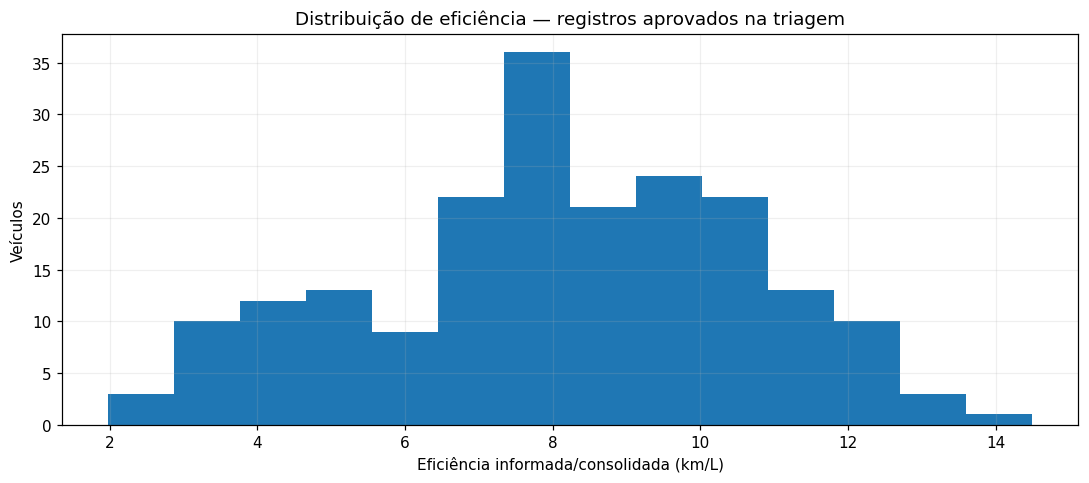

In [18]:
plt.figure(figsize=(10, 4.5))
plot_data = fleet.loc[fleet["valid_efficiency"], "kmpl"].dropna()
if len(plot_data):
    plt.hist(plot_data, bins=min(25, max(5, int(np.sqrt(len(plot_data))))))
plt.xlabel("Eficiência informada/consolidada (km/L)")
plt.ylabel("Veículos")
plt.title("Distribuição de eficiência — registros aprovados na triagem")
plt.tight_layout()
plt.show()

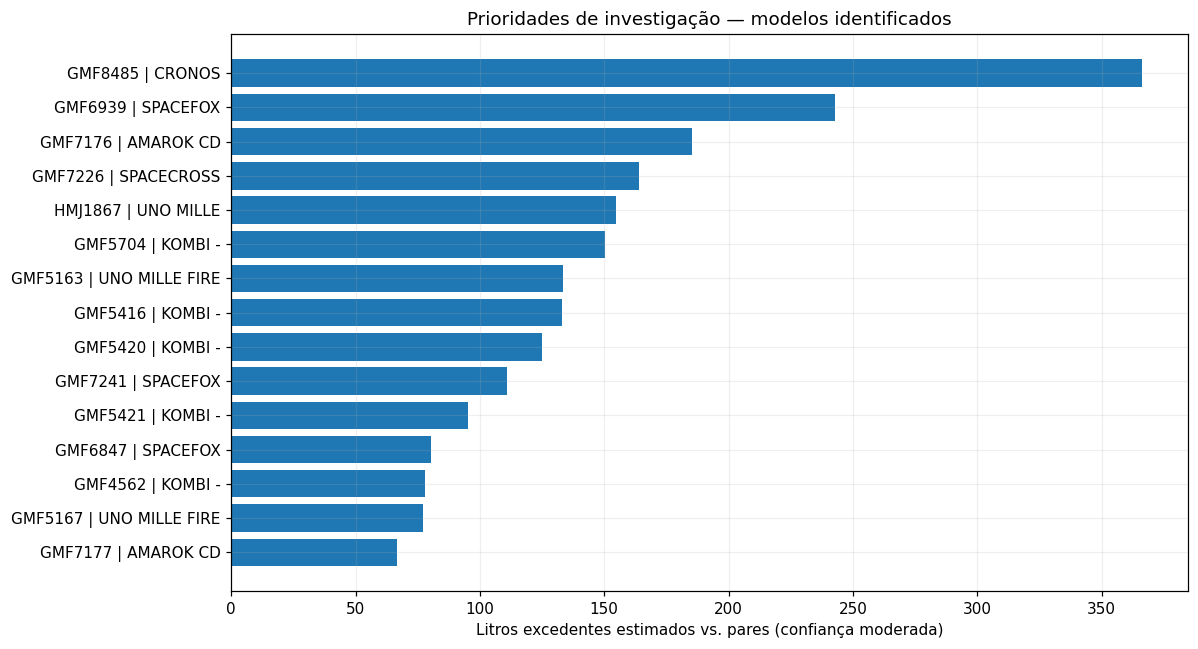

In [19]:
chart_actionable = top_actionable.head(15).sort_values("actionable_excess_liters_est")
if not chart_actionable.empty:
    plt.figure(figsize=(11, 6))
    labels = chart_actionable["fleet_id"] + " | " + chart_actionable["model"]
    plt.barh(labels, chart_actionable["actionable_excess_liters_est"])
    plt.xlabel("Litros excedentes estimados vs. pares (confiança moderada)")
    plt.title("Prioridades de investigação — modelos identificados")
    plt.tight_layout()
    plt.show()
else:
    print("Sem veículos elegíveis para o ranking interno de confiança moderada.")

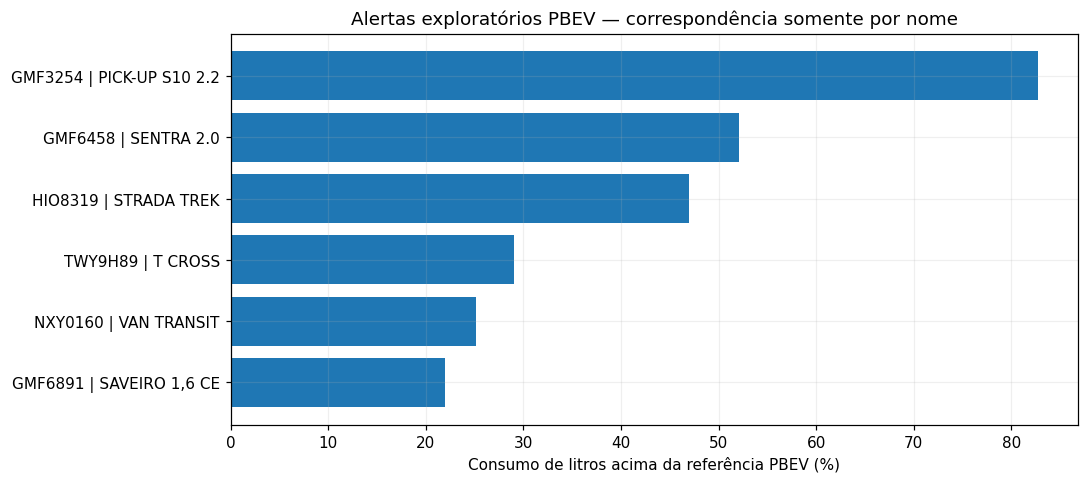

In [20]:
chart_pbev = fleet.loc[fleet["pbev_alert_exploratory"]].sort_values("pbev_excess_pct")
if not chart_pbev.empty:
    plt.figure(figsize=(10, max(4.5, len(chart_pbev) * 0.5)))
    labels = chart_pbev["fleet_id"] + " | " + chart_pbev["model"]
    plt.barh(labels, chart_pbev["pbev_excess_pct"] * 100)
    plt.xlabel("Consumo de litros acima da referência PBEV (%)")
    plt.title("Alertas exploratórios PBEV — correspondência somente por nome")
    plt.tight_layout()
    plt.show()
else:
    print("Sem alertas exploratórios PBEV para o limite configurado.")

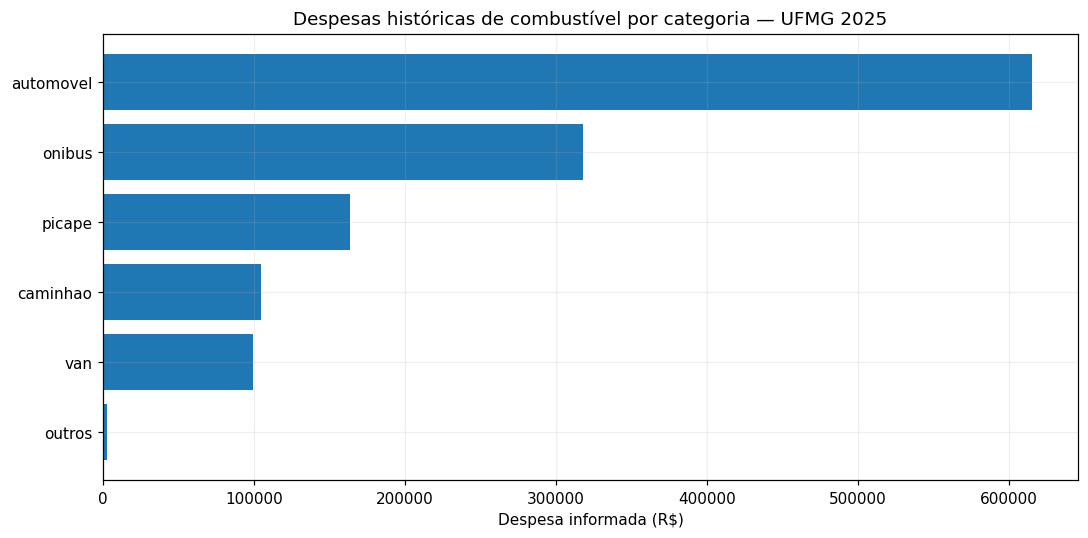

In [21]:
by_category = (
    fleet.groupby("vehicle_category", as_index=False)
    .agg(vehicles=("fleet_id", "count"), total_fuel_expense_2025=("fuel_expense", "sum"))
    .sort_values("total_fuel_expense_2025")
)
plt.figure(figsize=(10, 5))
plt.barh(by_category["vehicle_category"], by_category["total_fuel_expense_2025"])
plt.title("Despesas históricas de combustível por categoria — UFMG 2025")
plt.xlabel("Despesa informada (R$)")
plt.tight_layout()
plt.show()

## 10. Consulta individual

O painel detalha um veículo em contexto: registro original consolidado, elegibilidade, consumo informado, estimativas, pares, referência externa e cenários financeiros.

In [22]:
def vehicle_report(fleet_id: str) -> pd.DataFrame:
    found = fleet.loc[fleet["fleet_id"].eq(str(fleet_id).upper())]
    if found.empty:
        raise KeyError(f"Veículo {fleet_id!r} não encontrado.")
    cols = [
        "fleet_id", "model", "vehicle_category", "km", "km_covered", "km_uncovered",
        "kmpl", "liters_est", "liters_source", "fuel_expense", "total_expense",
        "fuel_cost_per_km_historical", "quality_status", "quality_reason",
        "provisional_duplicate_vehicle", "other_peer_count", "peer_median_kmpl",
        "peer_overuse_pct", "excess_liters_vs_peer_est", "peer_confidence",
        "peer_status", "peer_positive_liters_est", "priority_alert", "actionable_excess_liters_est", "exploratory_excess_liters_est",
        "pbev_model", "pbev_match_method", "pbev_min_kmpl",
        "pbev_excess_pct", "pbev_excess_liters_est", "pbev_comparison_confidence",
        "actionable_cost_gasolina_scenario_brl", "actionable_cost_etanol_scenario_brl",
        "actionable_cost_diesel_s10_scenario_brl",
    ]
    result = found[[c for c in cols if c in found.columns]].T
    display(result)
    return result

example_id = (
    top_actionable.iloc[0]["fleet_id"]
    if not top_actionable.empty else fleet.iloc[0]["fleet_id"]
)
vehicle_report(example_id)

,154
fleet_id,GMF8485
model,CRONOS
vehicle_category,automovel
km,"41,274.00"
km_covered,"41,274.00"
km_uncovered,0.00
kmpl,10.91
liters_est,"3,783.13"
liters_source,estimated_from_distance_and_reported_kmpl
fuel_expense,"24,595.77"


,154
fleet_id,GMF8485
model,CRONOS
vehicle_category,automovel
km,"41,274.00"
km_covered,"41,274.00"
km_uncovered,0.00
kmpl,10.91
liters_est,"3,783.13"
liters_source,estimated_from_distance_and_reported_kmpl
fuel_expense,"24,595.77"


## 11. Integração com o Fleet Force

O estudo utiliza os campos disponíveis na base pública. A integração com uma frota cliente poderá acrescentar tipos de despesas e informações operacionais que não estão presentes no relatório demonstrativo.

In [23]:
coverage_matrix = pd.DataFrame([
    ("Despesas com combustível", "Disponível", "Valor registrado em 2025"),
    ("Quilometragem", "Disponível", "Distância informada"),
    ("Manutenção e peças", "Disponível", "Valor registrado em 2025"),
    ("Litros abastecidos", "Estimado", "Derivado de distância / km/L"),
    ("Seguro", "Não disponível", "Não imputado"),
    ("Pedágio", "Não disponível", "Não imputado"),
    ("Multas", "Não disponível", "Não imputado"),
    ("Combustível por veículo", "Não disponível", "Cenários alternativos"),
], columns=["dimensao", "status", "uso_no_modelo"])
display(coverage_matrix)

,dimensao,status,uso_no_modelo
0,Despesas com combustível,Disponível,Valor registrado em 2025
1,Quilometragem,Disponível,Distância informada
2,Manutenção e peças,Disponível,Valor registrado em 2025
3,Litros abastecidos,Estimado,Derivado de distância / km/L
4,Seguro,Não disponível,Não imputado
5,Pedágio,Não disponível,Não imputado
6,Multas,Não disponível,Não imputado
7,Combustível por veículo,Não disponível,Cenários alternativos


## 12. Exportação dos resultados

Os arquivos gerados contêm os indicadores por veículo, o ranking de investigação, as referências utilizadas e dados de rastreabilidade para integração com dashboards e APIs.

In [24]:
EXPORT_FILES = {
    "fleet_vehicles.csv": fleet.drop(columns=["quality_reasons_list"], errors="ignore"),
    "fleet_quality.csv": quality_issues,
    "fleet_priority_ranking.csv": top_actionable,
    "fleet_comparison_groups.csv": model_groups,
    "fleet_public_comparisons.csv": fleet.loc[pbev_available, [
        "fleet_id", "model", "pbev_model", "pbev_match_method", "pbev_min_kmpl",
        "pbev_excess_pct", "pbev_excess_liters_est", "pbev_comparison_confidence"
    ]],
    "anp_reference_prices.csv": anp_prices.reset_index(),
    "fleet_summary.csv": summary,
    "fleet_scenarios.csv": scenario_summary,
    "fleet_data_coverage.csv": coverage_matrix,
}
for filename, dataframe in EXPORT_FILES.items():
    dataframe.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")

# Contratos básicos do processamento analítico.
assert fleet["fleet_id"].is_unique
assert not (fleet["priority_alert"] & fleet["peer_confidence"].ne("moderate")).any()
assert not (fleet["priority_alert"] & fleet["peer_overuse_pct"].lt(PEER_MODERATE_OVERUSE)).any()
assert not (fleet["priority_alert"] & fleet["actionable_excess_liters_est"].lt(MIN_PRIORITY_EXCESS_LITERS)).any()
assert not (fleet["peer_confidence"].eq("moderate") & fleet["model_identification_required"]).any()

print(f"{len(EXPORT_FILES)} tabelas prontas para integração em: {OUTPUT_DIR}")

9 tabelas prontas para integração em: /content/fleet_analysis_outputs


## 13. Interpretação do estudo

**US01 — Consolidação:** o modelo organiza valores, quilometragem, custo por km e volumes estimados por veículo, preservando informações de origem e qualidade.

**US02 — Comparação:** a referência interna utiliza o desempenho dos outros veículos com mesma identificação de modelo; comparações de identificação incompleta são exploratórias. A referência PBEV complementa a análise apenas para modelos leves elegíveis, com correspondência textual e cobertura limitada.

**US03 — Priorização:** desvios estatísticos relevantes geram uma lista de investigação e cenários alternativos em reais para dimensionar sua importância financeira. Os resultados não comprovam desperdício nem representam economia realizada.

**Escopo demonstrativo:** a frota UFMG não equivale à frota de 40 veículos da persona. Seguro, pedágio, multas, litros medidos e atributos completos de versão e uso não estão presentes na fonte. O objetivo deste notebook é demonstrar a metodologia analítica e o fluxo de dados que podem ser incorporados ao Fleet Force.